# Applied AI and Ethics Group Assignment - Tourism in Zeeland

**Group number:** 3 

---

## 0. Project setup

### 0.1 Import libraries

In [2]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

### 0.2 Load datasets

In [3]:
origin_by_municipality_by_month = pd.read_csv("Herkomst_per_gemeente_per_maand.csv", sep=";", encoding="latin-1")
origin_by_municipality = pd.read_csv("Herkomst_per_gemeente.csv", sep=";", encoding="latin-1")
cross_visitation_entire_period = pd.read_csv("Kruisbezoek_gehele_periode.csv", sep=";", encoding="latin-1")
cross_visitation_by_month = pd.read_csv("Kruisbezoek_per_maand.csv", sep=";", encoding="latin-1")
total_visits_by_month = pd.read_csv("Totaal_bezoek_per_maand.csv", sep=";", encoding="latin-1")
total_visits_by_week = pd.read_csv("Totaal_bezoek_per_week.csv", sep=";", encoding="latin-1")
service_Areas_PC4_per_month = pd.read_csv("Verzorgingsgebieden_PC4_per_maand.csv", sep=";", encoding="latin-1")

---

## 1. Business Understanding
### Situation description

### Business objective(s)
 


### Business success criteria

### Data mining goal(s)


### Data mining success criteria


---

## 2. Data Understanding

### 2.1 Data Composition

#### Dataset Composition

In [4]:
# How are missing values represented in the dataset?

dfs = [origin_by_municipality_by_month, origin_by_municipality, cross_visitation_entire_period, cross_visitation_by_month, total_visits_by_month, total_visits_by_week, service_Areas_PC4_per_month]

count_missing_values = 0
for df in dfs:
    count_missing_values += df.isnull().sum().sum()

print(f"Total missing values in the dataset: {count_missing_values}")

Total missing values in the dataset: 0


#### Variable Composition

In [5]:
def get_symbol_category(series: pd.Series) -> str:
  if pd.api.types.is_numeric_dtype(series):
    return "numeric"

  clean_s = series.dropna().astype(str).str.strip()
  if clean_s.empty:
    return "alphabetic"

  if pd.to_numeric(clean_s, errors="coerce").notna().all():
    return "numeric"

  if clean_s.str.contains(r"\d", regex=True).any():
    return "alphanumeric"

  return "alphabetic"

dictionary_symbol_types = {}

for df in dfs:
  for column in df.columns:
    if column not in dictionary_symbol_types:
      dictionary_symbol_types[column] = set()
    category = get_symbol_category(df[column])
    dictionary_symbol_types[column].add(category)

for variable, types in dictionary_symbol_types.items():
  print(f"Variable: {variable}, Type: {types}")

Variable: Location, Type: {'alphabetic'}
Variable: Locationcode, Type: {'alphanumeric'}
Variable: Resono-ID, Type: {'alphanumeric'}
Variable: Year, Type: {'numeric'}
Variable: Month, Type: {'numeric'}
Variable: Gemeentecode, Type: {'alphanumeric'}
Variable: Gemeentenaam, Type: {'alphabetic'}
Variable: Percentage_visits, Type: {'alphanumeric'}
Variable: Percentage_unique_visitors, Type: {'alphanumeric'}
Variable: Location1, Type: {'alphabetic'}
Variable: LocationCode1, Type: {'alphanumeric'}
Variable: Resono-ID1, Type: {'alphanumeric'}
Variable: Location2, Type: {'alphabetic'}
Variable: LocationCode2, Type: {'alphanumeric'}
Variable: Resono-ID2, Type: {'alphanumeric'}
Variable: Percentage, Type: {'alphanumeric'}
Variable: Visits, Type: {'numeric'}
Variable: Unique, Type: {'numeric'}
Variable: Recurring, Type: {'numeric'}
Variable: Week, Type: {'alphanumeric'}
Variable: Postalcode4, Type: {'numeric'}


### 2.2 Data exploration

##### Data Diversity

In [23]:
global_counts = {}

for df in dfs:

    for column in df.columns:
        # merging the information from :
        #   Location with Location1 and Location2
        #   Locationcode with Locationcode1 and Locationcode2
        #   Resono-ID with Resono-ID1 and Resono-ID2

        target_column = column
        match column:
            case "Location1" | "Location2":
                target_column = "Location"
            case "LocationCode1" | "LocationCode2":
                target_column = "Locationcode"
            case "Resono-ID1" | "Resono-ID2":
                target_column = "Resono-ID"
            case _:
                pass

        counts = df[column].value_counts()
        if target_column not in global_counts:
            global_counts[target_column] = counts
        else:
            global_counts[target_column] = global_counts[target_column].add(counts, fill_value=0)

dict_diversity = {}

for column, counts in global_counts.items():
    dict_diversity[column] = {
        "unique_values": len(counts),
        "least_frequent_value": counts.idxmin(),
        "least_frequent_count": int(counts.min()),
        "most_frequent_value": counts.idxmax(),
        "most_frequent_count": int(counts.max())
    }

for variable, diversity in dict_diversity.items():
    print(
        f"Variable: {variable} | "
        f"Unique: {diversity['unique_values']} | "
        f"Least Frequent: {diversity['least_frequent_value']} ({diversity['least_frequent_count']}) | "
        f"Most Frequent: {diversity['most_frequent_value']} ({diversity['most_frequent_count']})"
    )

Variable: Location | Unique: 37 | Least Frequent: Strand Veerse Dam (181) | Most Frequent: Centrum Goes (12551)
Variable: Locationcode | Unique: 32 | Least Frequent: location  (181) | Most Frequent: 02_001 (12551)
Variable: Resono-ID | Unique: 37 | Least Frequent: rcd052122P6996 (181) | Most Frequent: rcd038181P1861 (12551)
Variable: Year | Unique: 1 | Least Frequent: 2024 (91133) | Most Frequent: 2024 (91133)
Variable: Month | Unique: 12 | Least Frequent: 4 (5223) | Most Frequent: 7 (12632)
Variable: Gemeentecode | Unique: 343 | Least Frequent: GM0060 (2) | Most Frequent: GM0687 (409)
Variable: Gemeentenaam | Unique: 343 | Least Frequent: Ameland (2) | Most Frequent: Middelburg (409)
Variable: Percentage_visits | Unique: 1771 | Least Frequent: -0,02 (1) | Most Frequent: 0,02 (4687)
Variable: Percentage_unique_visitors | Unique: 1412 | Least Frequent: 10,02 (1) | Most Frequent: 0,03 (3735)
Variable: Percentage | Unique: 2054 | Least Frequent: 0,00 (1) | Most Frequent: 100,00 (517)
Vari

##### Data shape graph

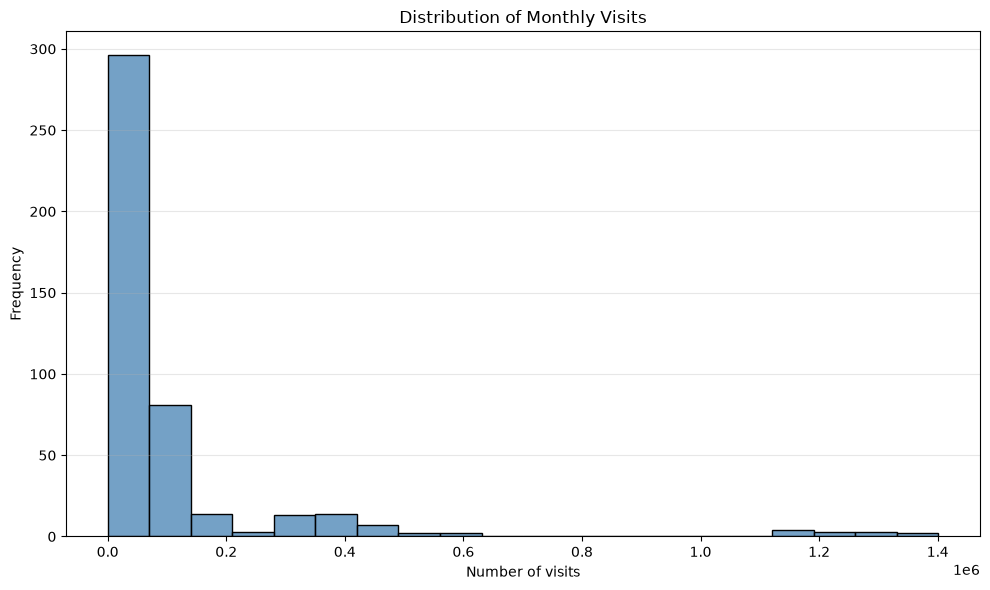

In [24]:
visits = total_visits_by_month["Visits"].dropna()

plt.figure(figsize=(10, 6))
sns.histplot(visits, bins=20, color="steelblue", edgecolor="black")
plt.title("Distribution of Monthly Visits")
plt.xlabel("Number of visits")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

##### Data Outliers Graph

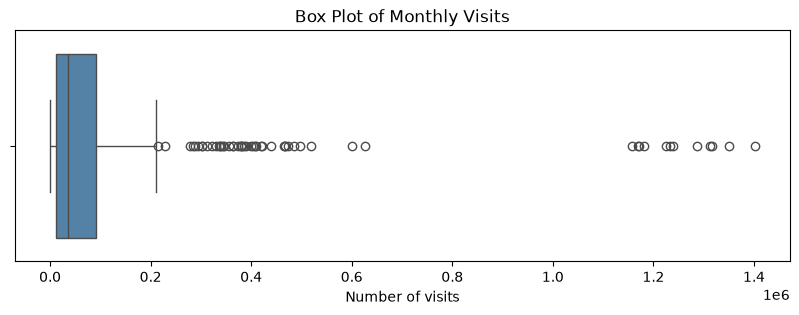

In [ ]:
plt.figure(figsize=(10, 3))
sns.boxplot(x=visits, color="steelblue")
plt.title("Box Plot of Monthly Visits")
plt.xlabel("Number of visits")
plt.show()